In [1]:
# 加载环境变量
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
from langchain_tavily import TavilySearch

# web搜索工具，使用tavily作为web搜索工具
web_search = TavilySearch(
    max_results=5,
    topic="general",
)

In [6]:
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

# 连接sqlite
connection = sqlite3.connect("../resources/personal_chief.db", check_same_thread=False)
# 初始化checkpointer
checkpointer = SqliteSaver(connection)
# 自动建表
checkpointer.setup()

In [7]:
from langchain.agents import create_agent

system_prompt = """
你是一名私人厨师。收到用户提供的食材照片或清单后，请按以下流程操作：
1.识别和评估食材：若用户提供照片，首先辨识所有可见食材。基于食材的外观状态，评估其新鲜度与可用量，整理出一份“当前可用食材清单”。
2.智能食谱检索：优先调用 web_search 工具，以“可用食材清单”为核心关键词，查找可行菜谱。
3.多维度评估与排序：从营养价值和制作难度两个维度对检索到的候选食谱进行量化打分，并根据得分排序，制作简单且营养丰富的排名靠前。
4.结构化方案输出：把排序后的食谱整理为一份结构清晰的建议报告，要包含食谱信息、得分、推荐理由、食谱的参考图片，帮助用户快速做出决策。

请严格按照流程，优先调用 web_search 工具搜索食谱，搜索不到的情况下才能自己发挥。
"""

agent = create_agent(
    model="deepseek-flash",
    tools=[web_search],
    system_prompt=system_prompt,
    checkpointer=checkpointer
)

In [10]:
from base64 import b64encode
from urllib.request import urlopen
from uuid import uuid4

from langchain.messages import HumanMessage

# 在本机下载冰箱图片，将图片数据直接随模型请求发送
image_url = "https://img.freepik.com/free-photo/arrangement-different-foods-organized-fridge_23-2149099882.jpg"
with urlopen(image_url, timeout=15) as image_response:
    media_type = image_response.headers.get_content_type()
    if media_type not in {"image/jpeg", "image/png", "image/gif", "image/webp"}:
        raise ValueError(f"链接返回的内容不是受支持的图片格式：{media_type}")
    image_base64 = b64encode(image_response.read()).decode("ascii")

multimodal_message = HumanMessage(
    content=[
        {
            "type": "image_url",
            "image_url": {"url": f"data:{media_type};base64,{image_base64}"},
        },
        {"type": "text", "text": "帮我看看这些食材能做些什么？"},
    ]
)

# 每次独立测试都开启新会话，避免重发历史消息中的图片链接
config = {"configurable": {"thread_id": str(uuid4())}}

response = agent.invoke({"messages": [multimodal_message]}, config)

================================ Human Message =================================

[{'type': 'image_url', 'image_url': {'url': ''}}, {'type': 'text', 'text': '帮我看看这些食材能做些什么？'}]
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_00_PqdRIgvnfi5LEC3BXjRZ2357)
 Call ID: call_00_PqdRIgvnfi5LEC3BXjRZ2357
  Args:
    query: 三文鱼 蘑菇 樱桃番茄 食谱 做法
    include_images: True
    search_depth: advanced
  tavily_search (call_01_tT9ECvpQijPDos6wt6Fj3507)
 Call ID: call_01_tT9ECvpQijPDos6wt6Fj3507
  Args:
    query: 鸡胸肉 西兰花 彩椒 洋葱 家常做法 食谱
    include_images: True
    search_depth: advanced
================================= Tool Message =================================
Name: tavily_search

{"query": "三文鱼 蘑菇 樱桃番茄 食谱 做法", "follow_up_questions": null, "answer": null, "images": ["https://i.redd.it/mf6lxfj0fp331.jpg", "https://i.ytimg.com/vi/4D2JNId_MCY/maxresdefault.jpg", "https://i.ytimg.com/vi/9ZD5UBwC9QU/maxresdefault.jpg", "https://lookaside.in
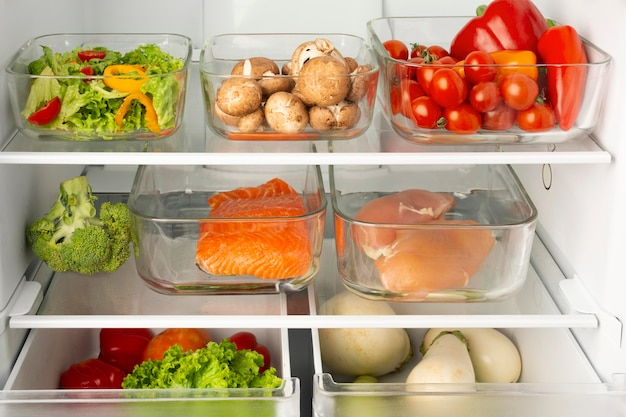

In [11]:
# 友好打印
for message in response['messages']:
    message.pretty_print()

In [12]:
response = agent.invoke(
    {"messages": [HumanMessage(content="我喜欢第1道菜，可以说的更详细点吗？")]},
    config
)

# 友好打印
response['messages'][-1].pretty_print()

================================== Ai Message ==================================

# 🥇 一锅端烤三文鱼蔬菜盘 · 完整详细版

> 参考来源：[尚食厨房（同盘烤鱼＋蔬菜）](https://www.youtube.com/watch?v=JvUFeVag4Zc)｜[烤三文鱼温度与熟度指南](https://getcookmatch.com/zh/recipe/baked-salmon)｜[烤蔬菜拼盘配方](https://www.facebook.com/recipewonderland/videos/1556208169878500)｜[百度百科·烤箱三文鱼技巧](https://baike.baidu.com/item/烤箱三文鱼/17175593)

---

## 一、这份量够 2–3 人吃

| 食材 | 用量 | 处理方式 |
|---|---|---|
| 三文鱼柳 | 2 块，约 400g（厚 2.5–3cm） | **不要去皮**，厨房纸彻底拍干 |
| 西兰花 | 约 300g（1 小颗） | 掰成 3–4cm 小朵，**先焯水 1 分钟** |
| 褐口蘑 | 约 200g（10–12 个） | 擦净不泡水，大的切半、小的整颗 |
| 小番茄 | 约 200g | 对半切（整颗烤容易爆汁烫嘴） |
| 红、橙彩椒 | 各半个 | 去籽，切 3cm 菱形块 |
| 黄洋葱 | 半个 | 切 1.5cm 宽的瓣（**不要切太碎，否则会烤焦**） |
| 大蒜 | 4 瓣 | 拍扁带皮（整瓣烤不会糊，香甜） |

**腌鱼调料（2 块鱼的量）**
- 橄榄油 1 大勺（15ml）
- 盐 ⅓ 小勺（约 2g）
- 现磨黑胡椒 ¼ 小勺
- 蒜粉 ½ 小勺（没有可用 1 瓣蒜末）
- 生抽或日式酱油 1 小勺（可不放，用来提鲜上色）
- 蜂蜜 ½ 小勺（可选，帮助上色，不放也很香）
- 柠檬汁 1 小勺 → **进烤箱前才刷**，不要提前腌

**拌蔬菜调料**
- 橄榄油 2 大勺（30ml）
- 盐 ½ 小勺
- 黑胡椒 ¼ 小勺
- 干香草（百里香、牛至、罗勒任一）1 小勺
- 蒜粉 ½ 小勺
- 柠檬皮屑少许（可选，很加分）

---

## 二、关键步骤

*